# Comparativa de modelos de fine-tuning

Este notebook carga automáticamente los resultados de **todos los experimentos de fine-tuning**
guardados en Drive y produce un informe comparativo completo primero en val y despues en test.

---
## 1. Configuración y dependencias

Se monta en Drive, importa librerías y define las rutas y constantes globales.

In [29]:
from google.colab import drive
import os
drive.mount('/content/drive')
assert os.path.exists('/content/drive/MyDrive'), 'Drive no montado'
print('Drive montado correctamente')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado correctamente


In [30]:
import warnings
warnings.filterwarnings('ignore')

import glob
import json
import torch
from pathlib import Path
from collections import Counter
from IPython.display import display, HTML

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_recall_fscore_support,
    cohen_kappa_score, confusion_matrix,
)

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    BitsAndBytesConfig, DataCollatorWithPadding
)
from peft import PeftModel
from torch.utils.data import DataLoader
from datasets import Dataset
import gc
print('Imports OK')

Imports OK


In [ ]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

In [31]:
TFM_DIR    = '/content/drive/MyDrive/TFM'
SPLITS_DIR = TFM_DIR + '/splits'
OUTPUT_DIR = TFM_DIR + '/comparativa'
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

LABEL2ID = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
CLASES   = ['IZQUIERDA', 'CENTRO', 'DERECHA']

PALETA_BASE = [
    '#185FA5', '#D85A30', '#1D9E75', '#7F77DD',
    '#BA7517', '#D4537E', '#639922', '#888780',
]

print(f'TFM_DIR    : {TFM_DIR}')
print(f'OUTPUT_DIR : {OUTPUT_DIR}')

TFM_DIR    : /content/drive/MyDrive/TFM
OUTPUT_DIR : /content/drive/MyDrive/TFM/comparativa


---
## 2. Carga automática de métricas

Busca todos los archivos `val_metrics.csv` dentro de las subcarpetas de `TFM_DIR`.
Cada notebook de fine-tuning guarda uno al finalizar el entrenamiento.

In [32]:
csv_paths = sorted(glob.glob(f'{TFM_DIR}/*/val_metrics.csv'))

if not csv_paths:
    raise FileNotFoundError(
        f'No se encontró ningún val_metrics.csv en {TFM_DIR}/*/\n'
        'Asegúrate de que los notebooks de fine-tuning han guardado sus métricas.'
    )

print(f'Modelos encontrados: {len(csv_paths)}')
for p in csv_paths:
    print(f'  {p}')

Modelos encontrados: 8
  /content/drive/MyDrive/TFM/qwen3_4b_lora/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_alllinear_r8/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_full7_r8/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp16/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_mlp32/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_r8_qkv/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_lora_regularized/val_metrics.csv
  /content/drive/MyDrive/TFM/qwen3_4b_qlora/val_metrics.csv


In [33]:
dfs = []
for p in csv_paths:
    df_tmp = pd.read_csv(p)
    if 'modelo' not in df_tmp.columns:
        df_tmp.insert(0, 'modelo', Path(p).parent.name)
    dfs.append(df_tmp)

df_metrics = pd.concat(dfs, ignore_index=True)
df_metrics = df_metrics.sort_values('f1_macro', ascending=False).reset_index(drop=True)
df_metrics.index = df_metrics.index + 1

n = len(df_metrics)
paleta = (PALETA_BASE * ((n // len(PALETA_BASE)) + 1))[:n]
df_metrics['color'] = paleta

print('Tabla de métricas cargada:')
cols_show = ['modelo', 'accuracy', 'f1_macro', 'f1_weighted', 'kappa', 'confianza', 'f1_izq', 'f1_cen', 'f1_der']
cols_show = [c for c in cols_show if c in df_metrics.columns]
print(df_metrics[cols_show].to_string())

Tabla de métricas cargada:
                       modelo  accuracy  f1_macro  f1_weighted   kappa  confianza  f1_izq  f1_cen  f1_der
1               Qwen3-4B_LoRA    0.8571    0.8556       0.8568  0.7808     0.9567  0.8415  0.8731  0.8522
2              Qwen3-4B_QLoRA    0.8571    0.8531       0.8566  0.7802     0.9597  0.8519  0.8756  0.8319
3         Qwen3-4B_LoRA_mlp32    0.8529    0.8484       0.8535  0.7761     0.9789  0.8690  0.8663  0.8099
4   Qwen3-4B_LoRA_regularized    0.8487    0.8460       0.8488  0.7689     0.9445  0.8383  0.8691  0.8305
5         Qwen3-4B_LoRA_mlp16    0.8319    0.8324       0.8316  0.7436     0.8903  0.8148  0.8394  0.8430
6      Qwen3-4B_LoRA_full7_r8    0.8319    0.8295       0.8309  0.7409     0.9753  0.8025  0.8571  0.8288
7        Qwen3-4B_LoRA_r8_qkv    0.8235    0.8216       0.8235  0.7311     0.9628  0.8125  0.8394  0.8130
8  Qwen3-4B_LoRA_alllinear_r8    0.8235    0.8213       0.8232  0.7289     0.9701  0.8072  0.8426  0.8142


---
## 0. Extracción automática de hiperparámetros

Antes de comparar resultados recordamos que  saber se cambió en cada experimento.
Esta sección lee los archivos que HuggingFace Trainer guarda automáticamente en cada carpeta
y construye una tabla comparativa de hiperparámetros sin necesidad de introducir nada manualmente.

- `config.json`  Modelo base, cuantización (detecta QLoRA automáticamente
- `adapter_config.json` Rango r, alpha, dropout, módulos objetivo
- `training_args.bin` Learning rate, épocas, batch size, weight decay, warmup
- `trainer_state.json` Mejor época y F1-macro del mejor checkpoint

In [34]:
def extraer_hiperparametros(modelo_dir: str, nombre_modelo: str) -> dict:
    """
    Extrae hiperparámetros de una carpeta de modelo guardada por HuggingFace Trainer.
    Si algún archivo no existe devuelve '—' para ese campo en lugar de lanzar un error.
    """
    params = {'modelo': nombre_modelo}

    # Carpetas candidatas en orden de prioridad
    candidatas = [modelo_dir]
    best_model = os.path.join(modelo_dir, 'best_model')
    if os.path.isdir(best_model):
        candidatas.insert(0, best_model)
    checkpoints = sorted(glob.glob(os.path.join(modelo_dir, 'checkpoint-*')))
    if checkpoints:
        candidatas.insert(0, checkpoints[-1])

    def buscar_json(nombre_archivo):
        """Busca un JSON en todas las carpetas candidatas y devuelve el primero que encuentre."""
        for carpeta in candidatas:
            p = os.path.join(carpeta, nombre_archivo)
            if os.path.exists(p):
                with open(p, 'r') as f:
                    return json.load(f)
        return None

    # Modelo base y cuantización (config.json)
    config = buscar_json('config.json')
    if config:
        params['modelo_base'] = config.get('_name_or_path', config.get('model_type', '?'))
        qconfig = config.get('quantization_config', {})
        if qconfig:
            params['cuantizacion'] = qconfig.get('quant_type', '?').upper()
            params['bits']         = '4-bit NF4' if qconfig.get('load_in_4bit') else \
                                     '8-bit'     if qconfig.get('load_in_8bit') else '?'
            params['double_quant'] = qconfig.get('bnb_4bit_use_double_quant', False)
        else:
            params['cuantizacion'] = 'ninguna'
            params['bits']         = 'bfloat16'
            params['double_quant'] = False
    else:
        params['modelo_base']  = '—'
        params['cuantizacion'] = '—'
        params['bits']         = '—'

    # Configuración LoRA
    adapter = buscar_json('adapter_config.json')
    if adapter:
      cuant = params.get('cuantizacion', '—')
      es_qlora = cuant not in ('—', 'ninguna', '')

      if cuant == '—':
        nombre_lower = nombre_modelo.lower()
        es_qlora = 'qlora' in nombre_lower or 'q_lora' in nombre_lower

      params['lora_tipo']      = 'QLoRA' if es_qlora else 'LoRA'
      params['lora_r']         = adapter.get('r', '?')
      params['lora_alpha']     = adapter.get('lora_alpha', '?')
      params['lora_dropout']   = adapter.get('lora_dropout', '?')
      params['target_modules'] = ', '.join(sorted(adapter.get('target_modules', [])))
      params['bias']           = adapter.get('bias', '?')

    else:
      for k in ['lora_tipo','lora_r','lora_alpha','lora_dropout','target_modules','bias']:
        params[k] = '—'

    # Training arguments
    args_cargado = False
    for carpeta in candidatas:
        args_path = os.path.join(carpeta, 'training_args.bin')
        if os.path.exists(args_path):
            try:
                args = torch.load(args_path, map_location='cpu', weights_only=False)
                params['learning_rate']                = args.learning_rate
                params['num_train_epochs']             = int(args.num_train_epochs)
                params['per_device_train_batch_size']  = args.per_device_train_batch_size
                params['gradient_accumulation_steps']  = args.gradient_accumulation_steps
                params['batch_efectivo']               = (args.per_device_train_batch_size *
                                                          args.gradient_accumulation_steps)
                params['weight_decay']                 = args.weight_decay
                params['warmup_ratio']                 = round(getattr(args, 'warmup_ratio', 0), 3)
                params['bf16']                         = getattr(args, 'bf16', False)
                params['gradient_checkpointing']       = getattr(args, 'gradient_checkpointing', False)
                params['metric_for_best_model']        = getattr(args, 'metric_for_best_model', '?')
                args_cargado = True
            except Exception as e:
                params['_error_args'] = str(e)
            break

    if not args_cargado:
        for k in ['learning_rate','num_train_epochs','batch_efectivo',
                  'weight_decay','warmup_ratio','bf16','gradient_checkpointing']:
            params[k] = '—'
        params['_nota'] = 'training_args.bin no encontrado'

    #Mejor época (trainer_state.json)
    state = buscar_json('trainer_state.json')
    if state:
        log_history = state.get('log_history', [])
        val_logs    = [x for x in log_history if 'eval_f1_macro' in x]
        if val_logs:
            f1_vals  = [x['eval_f1_macro'] for x in val_logs]
            epocas   = [x['epoch']         for x in val_logs]
            best_idx = f1_vals.index(max(f1_vals))
            params['mejor_epoca']             = epocas[best_idx]
            params['f1_macro_val']            = round(max(f1_vals), 4)
            params['total_epocas_entrenadas'] = len(val_logs)
        else:
            params['mejor_epoca']  = '—'
            params['f1_macro_val'] = '—'
    else:
        params['mejor_epoca']  = '—'
        params['f1_macro_val'] = '—'

    return params

print('Función extraer_hiperparametros() definida')

Función extraer_hiperparametros() definida


In [35]:
todos_params = []

for csv_p in csv_paths:
    df_tmp  = pd.read_csv(csv_p)
    nombre  = df_tmp.get('modelo', pd.Series([Path(csv_p).parent.name])).iloc[0]
    mod_dir = str(Path(csv_p).parent)

    p = extraer_hiperparametros(mod_dir, nombre)
    todos_params.append(p)

    # Comprobar qué archivos se encontraron
    archivos_ko = []
    for archivo in ['adapter_config.json','training_args.bin','trainer_state.json']:
        encontrado = any(
            os.path.exists(os.path.join(d, archivo))
            for d in [
                mod_dir,
                os.path.join(mod_dir, 'best_model'),
                *sorted(glob.glob(os.path.join(mod_dir, 'checkpoint-*')))
            ]
        )
        if not encontrado:
            archivos_ko.append(archivo)

    estado = 'OK   ' if not archivos_ko else 'AVISO'
    print(f'  {estado}  {nombre}')
    if archivos_ko:
        print(f'         No encontrado: {archivos_ko}')

print(f'\nTotal: {len(todos_params)} modelos procesados')

  OK     Qwen3-4B_LoRA
  OK     Qwen3-4B_LoRA_alllinear_r8
  OK     Qwen3-4B_LoRA_full7_r8
  OK     Qwen3-4B_LoRA_mlp16
  OK     Qwen3-4B_LoRA_mlp32
  OK     Qwen3-4B_LoRA_r8_qkv
  OK     Qwen3-4B_LoRA_regularized
  OK     Qwen3-4B_QLoRA

Total: 8 modelos procesados


### Tabla de hiperparámetros

In [36]:
def valor_fmt(v):
    if isinstance(v, bool):   return 'SI' if v else 'NO'
    if isinstance(v, float):
        if v == 0:            return '0'
        if v < 0.001:         return f'{v:.2e}'
        if v < 1:             return f'{v:.4f}'
        return f'{v:.2f}'
    return str(v) if v is not None else '—'

GRUPOS = [
    ('Arquitectura', [
        ('modelo_base',             'Modelo base'),
        ('lora_tipo',               'Tipo de adaptación'),
        ('cuantizacion',            'Cuantización'),
        ('bits',                    'Precisión'),
        ('double_quant',            'Double quantization'),
    ]),
    ('LoRA', [
        ('lora_r',                  'Rango r'),
        ('lora_alpha',              'Alpha'),
        ('lora_dropout',            'Dropout'),
        ('target_modules',          'Módulos objetivo'),
        ('bias',                    'Bias'),
    ]),
    ('Entrenamiento', [
        ('learning_rate',           'Learning rate'),
        ('num_train_epochs',        'Épocas configuradas'),
        ('total_epocas_entrenadas', 'Épocas entrenadas'),
        ('mejor_epoca',             'Mejor época'),
        ('batch_efectivo',          'Batch efectivo'),
        ('per_device_train_batch_size', 'Batch por dispositivo'),
        ('gradient_accumulation_steps', 'Grad. accumulation steps'),
        ('weight_decay',            'Weight decay'),
        ('warmup_ratio',            'Warmup ratio'),
        ('bf16',                    'BF16'),
        ('gradient_checkpointing',  'Grad. checkpointing'),
        ('metric_for_best_model',   'Métrica de selección'),
    ]),
    ('Resultado validación', [
        ('f1_macro_val',            'F1-macro (mejor checkpoint)'),
    ]),
]

nombres = [p['modelo'] for p in todos_params]

s_th    = 'padding:8px 14px;text-align:left;background:#f4f4f4;font-weight:500;font-size:13px;border-bottom:2px solid #ddd;white-space:nowrap'
s_th_c  = 'padding:8px 14px;text-align:center;background:#f4f4f4;font-weight:500;font-size:13px;border-bottom:2px solid #ddd;white-space:nowrap'
s_td    = 'padding:6px 14px;text-align:center;border-bottom:0.5px solid #eee;font-size:13px;white-space:nowrap'
s_label = 'padding:6px 14px;text-align:left;color:#555;font-size:12px;border-bottom:0.5px solid #eee;white-space:nowrap'
s_group = 'padding:8px 14px;font-weight:500;font-size:11px;background:#fafafa;letter-spacing:0.08em;text-transform:uppercase;color:#888;border-bottom:0.5px solid #e8e8e8'
s_best  = 'padding:6px 14px;text-align:center;border-bottom:0.5px solid #eee;font-size:13px;white-space:nowrap;background:#e8f5e9;font-weight:500;color:#2e7d32'
s_diff  = 'color:#185FA5;font-weight:500'

header = f'<tr><th style="{s_th}">Hiperparámetro</th>'
for n in nombres:
    header += f'<th style="{s_th_c}">{n.replace("_"," ")}</th>'
header += '</tr>'
leyenda = '<p style="font-size:11px;color:#888;margin-bottom:6px;">Valores que difieren entre modelos destacados en azul &nbsp;|&nbsp; Mejor resultado marcado en verde</p>'

body = ''
for grupo_nombre, campos in GRUPOS:
    body += f'<tr><td colspan="{len(nombres)+1}" style="{s_group}">{grupo_nombre}</td></tr>'
    for clave, etiqueta in campos:
        vals     = [p.get(clave, '—') for p in todos_params]
        vals_fmt = [valor_fmt(v) for v in vals]
        if all(v == '—' for v in vals_fmt):
            continue
        vals_validos  = [v for v in vals_fmt if v != '—']
        hay_variacion = len(set(vals_validos)) > 1
        es_resultado  = grupo_nombre == 'Resultado validación'
        mejor_val = None
        if es_resultado:
            try:    mejor_val = max(float(v) for v in vals_fmt if v != '—')
            except: pass
        row = f'<td style="{s_label}">{etiqueta}</td>'
        for v_fmt in vals_fmt:
            try:    es_mejor = es_resultado and mejor_val and abs(float(v_fmt) - mejor_val) < 1e-6
            except: es_mejor = False
            if es_mejor:
                row += f'<td style="{s_best}">{v_fmt} ✓</td>'
            elif hay_variacion and v_fmt != '—':
                row += f'<td style="{s_td}"><span style="{s_diff}">{v_fmt}</span></td>'
            else:
                row += f'<td style="{s_td}">{v_fmt}</td>'
        body += f'<tr>{row}</tr>'

display(HTML(f'''
<div style="overflow-x:auto;margin-top:1rem">
{leyenda}
<table style="border-collapse:collapse;font-size:13px;width:100%;min-width:500px">
  <thead>{header}</thead>
  <tbody>{body}</tbody>
</table></div>
'''))

---
## 3. Gráficas de métricas globales

Barras horizontales de F1-macro, accuracy y kappa para todos los modelos.
El eje X empieza en 0.5 para ampliar las diferencias, que suelen concentrarse
en una banda estrecha cuando todos los modelos son variantes del mismo experimento.

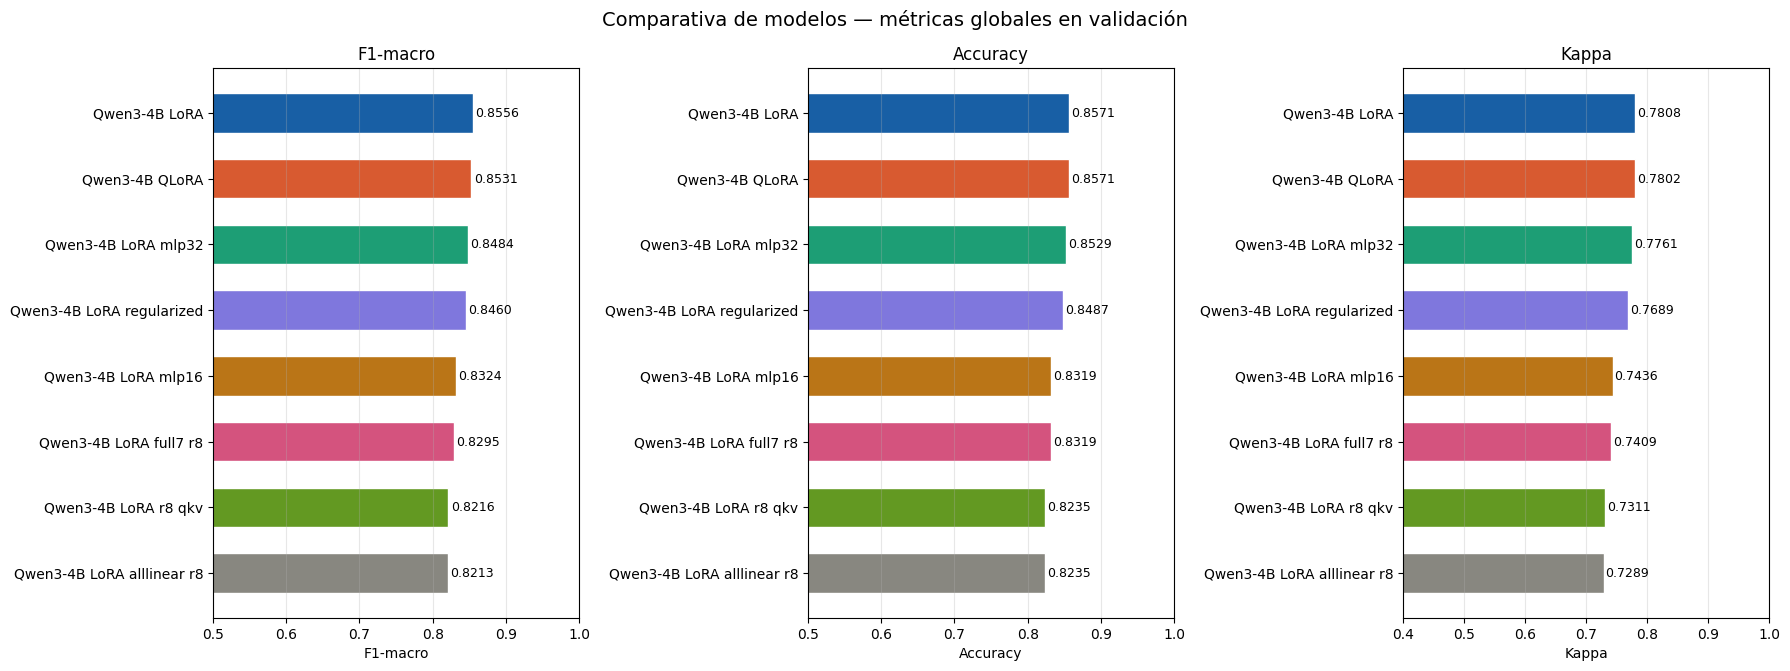

Guardado: /content/drive/MyDrive/TFM/comparativa/comparativa_metricas_globales.png


In [38]:
modelos  = df_metrics['modelo'].tolist()
colores  = df_metrics['color'].tolist()
n_models = len(modelos)
x = np.arange(n_models)

fig, axes = plt.subplots(1, 3, figsize=(18, max(5, n_models * 0.6 + 2)))

for ax, (col, label, ymin) in zip(axes, [
    ('f1_macro',  'F1-macro',  0.5),
    ('accuracy',  'Accuracy',  0.5),
    ('kappa',     'Kappa',     0.4),
]):
    vals = df_metrics[col].tolist()
    bars = ax.barh(x, vals, color=colores, edgecolor='white', height=0.6)
    ax.set_yticks(x)
    ax.set_yticklabels([m.replace('_', ' ') for m in modelos], fontsize=10)
    ax.set_xlabel(label)
    ax.set_xlim(ymin, 1.0)
    ax.set_title(label, fontsize=12)
    ax.grid(True, axis='x', alpha=0.3)
    ax.invert_yaxis()
    for bar, val in zip(bars, vals):
        ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

plt.suptitle('Comparativa de modelos — métricas globales en validación', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/comparativa_metricas_globales.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Guardado: {OUTPUT_DIR}/comparativa_metricas_globales.png')

---
## 4. F1 por clase ideológica

Un modelo puede tener buen F1-macro pero fallar sistemáticamente en una clase concreta.
Esta gráfica desglosa el F1 por IZQUIERDA, CENTRO y DERECHA para detectar ese patrón.

En clasificación ideológica, un F1 bajo en DERECHA es el problema más frecuente
porque es la clase menos representada en el dataset (24% del entrenamiento).

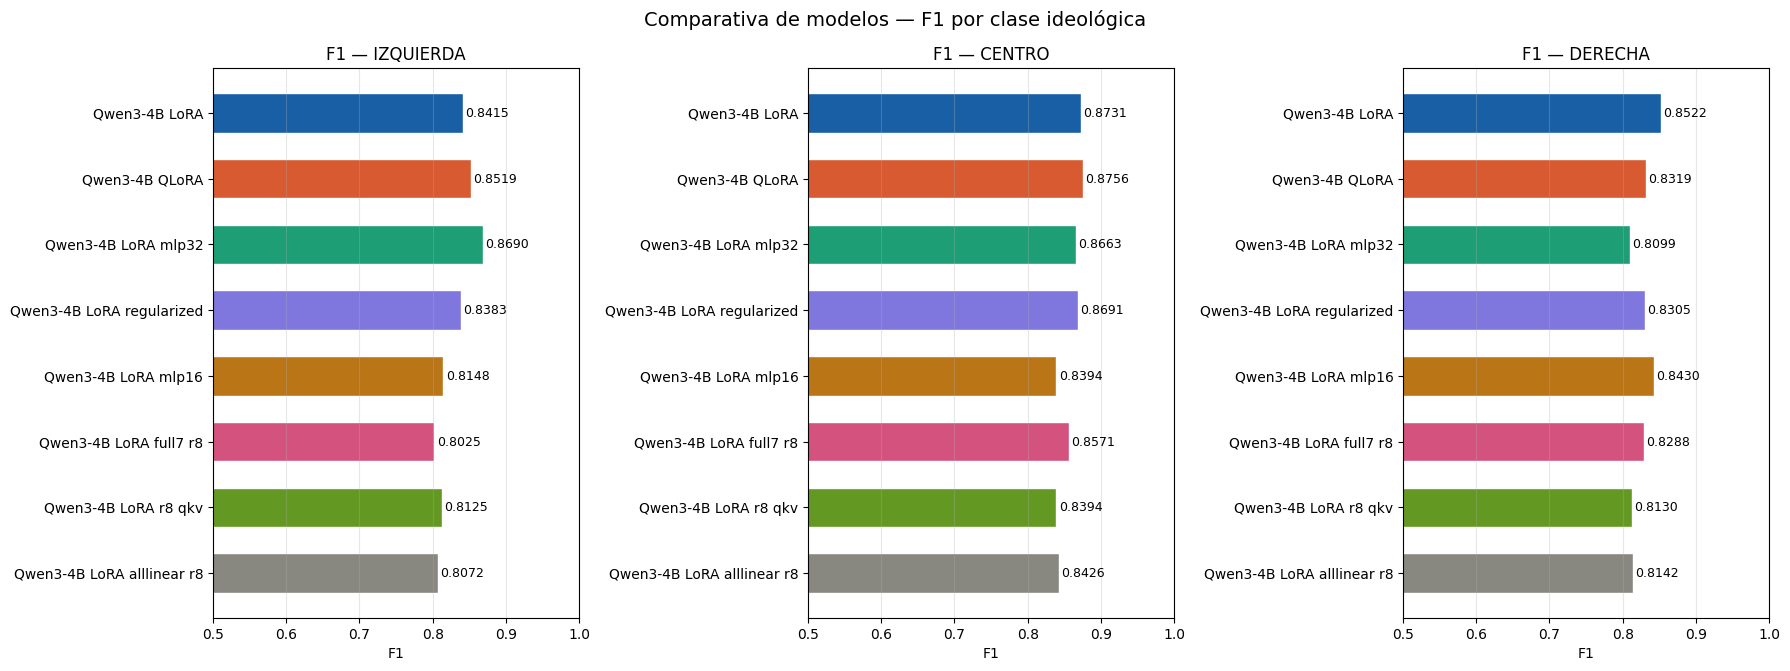

Guardado: /content/drive/MyDrive/TFM/comparativa/comparativa_f1_por_clase.png


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, max(5, n_models * 0.6 + 2)))

for ax, (cls_col, cls_name) in zip(axes, [
    ('f1_izq', 'IZQUIERDA'),
    ('f1_cen', 'CENTRO'),
    ('f1_der', 'DERECHA'),
]):
    vals = df_metrics[cls_col].tolist()
    bars = ax.barh(x, vals, color=colores, edgecolor='white', height=0.6)
    ax.set_yticks(x)
    ax.set_yticklabels([m.replace('_', ' ') for m in modelos], fontsize=10)
    ax.set_xlabel('F1')
    ax.set_xlim(0.5, 1.0)
    ax.set_title(f'F1 — {cls_name}', fontsize=12)
    ax.grid(True, axis='x', alpha=0.3)
    ax.invert_yaxis()
    for bar, val in zip(bars, vals):
        ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=9)

plt.suptitle('Comparativa de modelos — F1 por clase ideológica', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/comparativa_f1_por_clase.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Guardado: {OUTPUT_DIR}/comparativa_f1_por_clase.png')

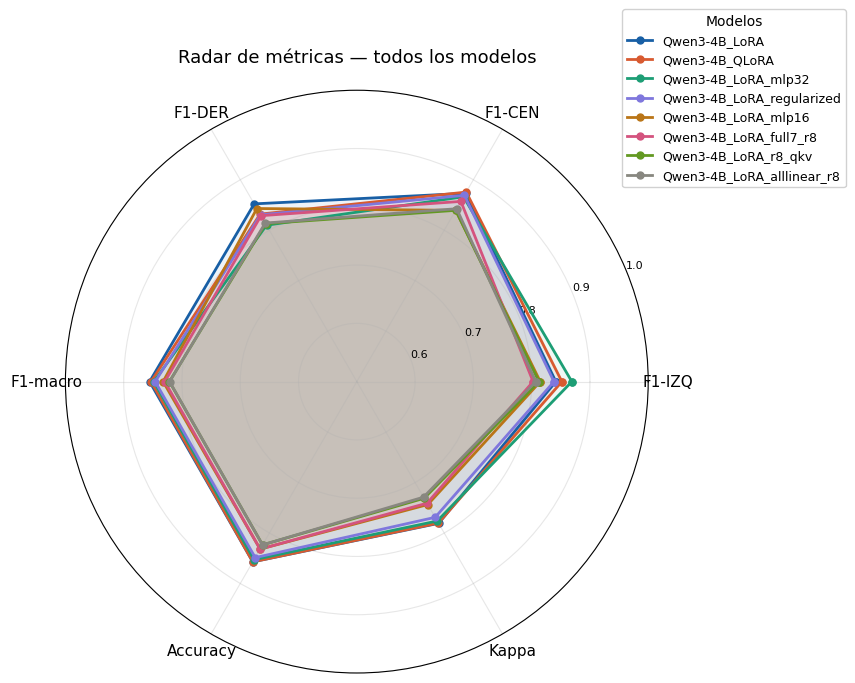

Guardado: /content/drive/MyDrive/TFM/comparativa/radar_metricas.png


In [40]:
categorias  = ['F1-IZQ', 'F1-CEN', 'F1-DER', 'F1-macro', 'Accuracy', 'Kappa']
cols_radar  = ['f1_izq', 'f1_cen', 'f1_der',  'f1_macro', 'accuracy', 'kappa']
N       = len(categorias)
angulos = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

for (_, row), color in zip(df_metrics.iterrows(), colores):
    vals  = [row[c] for c in cols_radar] + [row[cols_radar[0]]]
    ax.plot(angulos, vals, 'o-', linewidth=2, color=color,
            label=row['modelo'], markersize=5)
    ax.fill(angulos, vals, alpha=0.07, color=color)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(categorias, fontsize=11)
ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_yticklabels(['0.6','0.7','0.8','0.9','1.0'], fontsize=8)
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=9,
          framealpha=0.9, title='Modelos')
ax.set_title('Radar de métricas — todos los modelos', fontsize=13, pad=20)

plt.tight_layout()
fig.savefig(OUTPUT_DIR + '/radar_metricas.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Guardado: {OUTPUT_DIR}/radar_metricas.png')

---
## 5. Curvas de aprendizaje y detección de overfitting

Carga el `trainer_state.json` de cada modelo para comparar la evolución del F1-macro
y la validation loss por época en todos los experimentos a la vez.

In [41]:
def cargar_log_history(modelo_dir):
    """
    Carga el historial de validación desde trainer_state.json.
    Busca en el último checkpoint y en la raíz del modelo.
    Devuelve (epocas, f1_vals, val_loss_vals) o None si no lo encuentra.
    """
    candidatos = [os.path.join(modelo_dir, 'trainer_state.json')]
    for ckpt in sorted(glob.glob(os.path.join(modelo_dir, 'checkpoint-*'))):
        candidatos.append(os.path.join(ckpt, 'trainer_state.json'))

    for path in reversed(candidatos):
        if os.path.exists(path):
            with open(path, 'r') as f:
                state = json.load(f)
            val_logs = [x for x in state.get('log_history', []) if 'eval_f1_macro' in x]
            if val_logs:
                return (
                    [x['epoch']         for x in val_logs],
                    [x['eval_f1_macro'] for x in val_logs],
                    [x.get('eval_loss') for x in val_logs],
                    state.get('log_history', []),
                )
    return None

curvas = {}
for _, row in df_metrics.iterrows():
    nombre = row['modelo']
    for csv_p in csv_paths:
        df_tmp  = pd.read_csv(csv_p)
        mod_csv = df_tmp.get('modelo', pd.Series([Path(csv_p).parent.name])).iloc[0]
        if mod_csv == nombre:
            resultado = cargar_log_history(str(Path(csv_p).parent))
            if resultado:
                curvas[nombre] = resultado
                print(f'  OK  {nombre}: {len(resultado[0])} épocas')
            else:
                print(f'  --  {nombre}: trainer_state.json no encontrado')
            break

print(f'\nCurvas disponibles: {len(curvas)}/{n_models}')

  OK  Qwen3-4B_LoRA: 10 épocas
  OK  Qwen3-4B_QLoRA: 10 épocas
  OK  Qwen3-4B_LoRA_mlp32: 10 épocas
  OK  Qwen3-4B_LoRA_regularized: 8 épocas
  OK  Qwen3-4B_LoRA_mlp16: 10 épocas
  OK  Qwen3-4B_LoRA_full7_r8: 10 épocas
  OK  Qwen3-4B_LoRA_r8_qkv: 10 épocas
  OK  Qwen3-4B_LoRA_alllinear_r8: 10 épocas

Curvas disponibles: 8/8


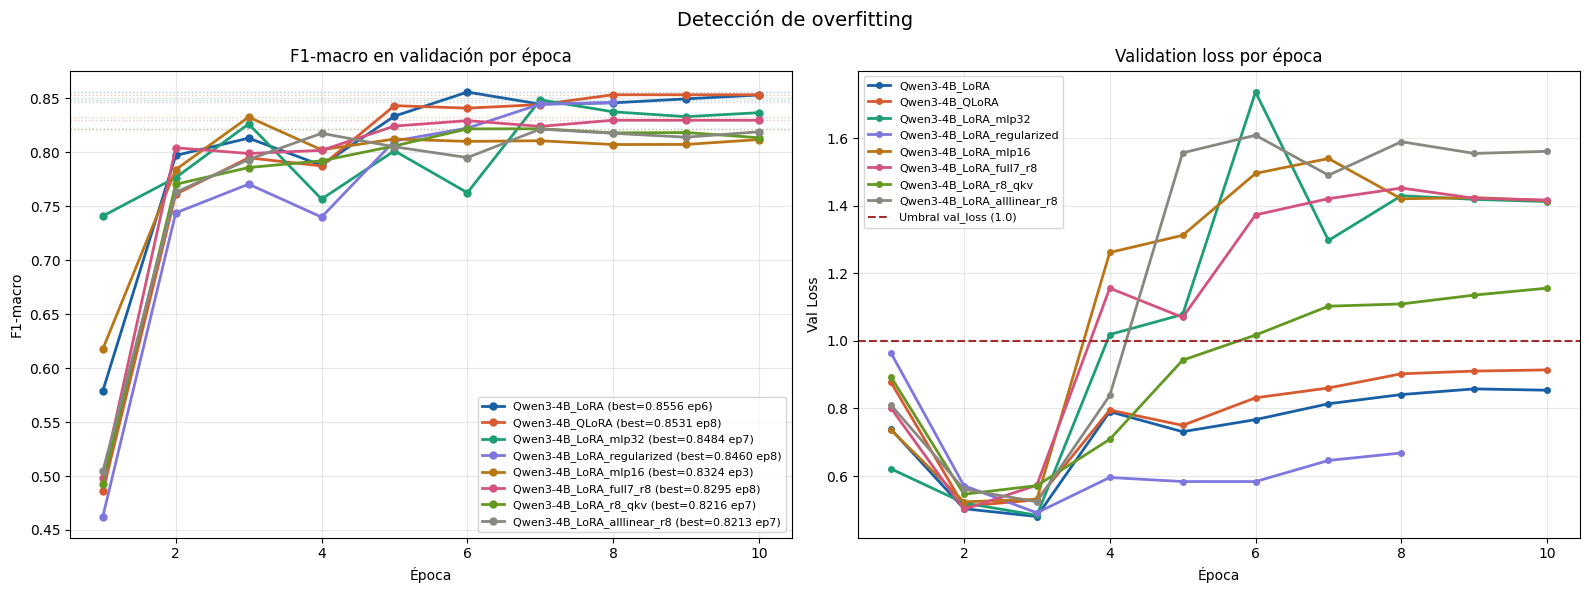

Guardado: /content/drive/MyDrive/TFM/comparativa/overfitting_cruzado.png

Modelo                                  Loss min  Loss final  Subida  F1 best  Diagnóstico
------------------------------------------------------------------------------------------
  Qwen3-4B_LoRA                            0.480       0.854   0.374   0.8556  MEDIO
  Qwen3-4B_QLoRA                           0.511       0.914   0.404   0.8531  MEDIO
  Qwen3-4B_LoRA_mlp32                      0.484       1.413   0.929   0.8484  BASTANTE
  Qwen3-4B_LoRA_regularized                0.491       0.668   0.177   0.8460  OK
  Qwen3-4B_LoRA_mlp16                      0.524       1.416   0.892   0.8324  BASTANTE
  Qwen3-4B_LoRA_full7_r8                   0.501       1.417   0.916   0.8295  BASTANTE
  Qwen3-4B_LoRA_r8_qkv                     0.546       1.156   0.610   0.8216  MEDIO
  Qwen3-4B_LoRA_alllinear_r8               0.524       1.562   1.038   0.8213  BASTANTE


In [42]:
UMBRAL_VAL_LOSS = 1.0  # val_loss por encima de esto es señal de overfitting
resumen_overfitting = []

if curvas:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for nombre, (epocas, f1_vals, val_loss, log_history) in curvas.items():
        color    = df_metrics.loc[df_metrics['modelo'] == nombre, 'color'].values[0]
        mejor_f1 = max(f1_vals)
        mejor_ep = epocas[f1_vals.index(mejor_f1)]

        axes[0].plot(epocas, f1_vals, 'o-', linewidth=2, markersize=5, color=color,
                     label=f'{nombre} (best={mejor_f1:.4f} ep{mejor_ep:.0f})')
        axes[0].axhline(mejor_f1, color=color, linestyle=':', alpha=0.35, linewidth=1)

        val_logs = [x for x in log_history if 'eval_f1_macro' in x]
        if not val_logs:
            continue

        val_loss_ep = [x['eval_loss'] for x in val_logs]
        f1_ep       = [x['eval_f1_macro'] for x in val_logs]

        axes[1].plot(epocas, val_loss_ep, 'o-', linewidth=2, color=color, label=nombre, markersize=4)

        # Detectar overfitting: val_loss sube entre época 3 y el final
        subida = val_loss_ep[-1] - min(val_loss_ep)
        flag   = 'BASTANTE' if subida > 0.8 else ('MEDIO' if subida > 0.3 else 'OK')

        resumen_overfitting.append({
            'modelo':      nombre,
            'val_loss_min': round(min(val_loss_ep), 3),
            'val_loss_fin': round(val_loss_ep[-1], 3),
            'subida':       round(subida, 3),
            'f1_best':      round(max(f1_vals), 4),
            'diagnostico':  flag,
        })

    axes[0].set_xlabel('Época');  axes[0].set_ylabel('F1-macro')
    axes[0].set_title('F1-macro en validación por época')
    axes[0].legend(fontsize=8);   axes[0].grid(True, alpha=0.3)

    axes[1].axhline(UMBRAL_VAL_LOSS, color='#A32D2D', linewidth=1.5, linestyle='--',
                    label=f'Umbral val_loss ({UMBRAL_VAL_LOSS})')
    axes[1].set_xlabel('Época');  axes[1].set_ylabel('Val Loss')
    axes[1].set_title('Validation loss por época')
    axes[1].legend(fontsize=8);   axes[1].grid(True, alpha=0.3)

    plt.suptitle('Detección de overfitting', fontsize=14)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/overfitting_cruzado.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {OUTPUT_DIR}/overfitting_cruzado.png')

    if resumen_overfitting:
        print(f'\n{"Modelo":<38} {"Loss min":>9} {"Loss final":>11} {"Subida":>7} {"F1 best":>8}  Diagnóstico')
        print('-' * 90)
        for r in resumen_overfitting:
            print(f'  {r["modelo"]:<36} {r["val_loss_min"]:>9.3f} {r["val_loss_fin"]:>11.3f} '
                  f'{r["subida"]:>7.3f} {r["f1_best"]:>8.4f}  {r["diagnostico"]}')
else:
    print('No hay datos de curvas disponibles.')

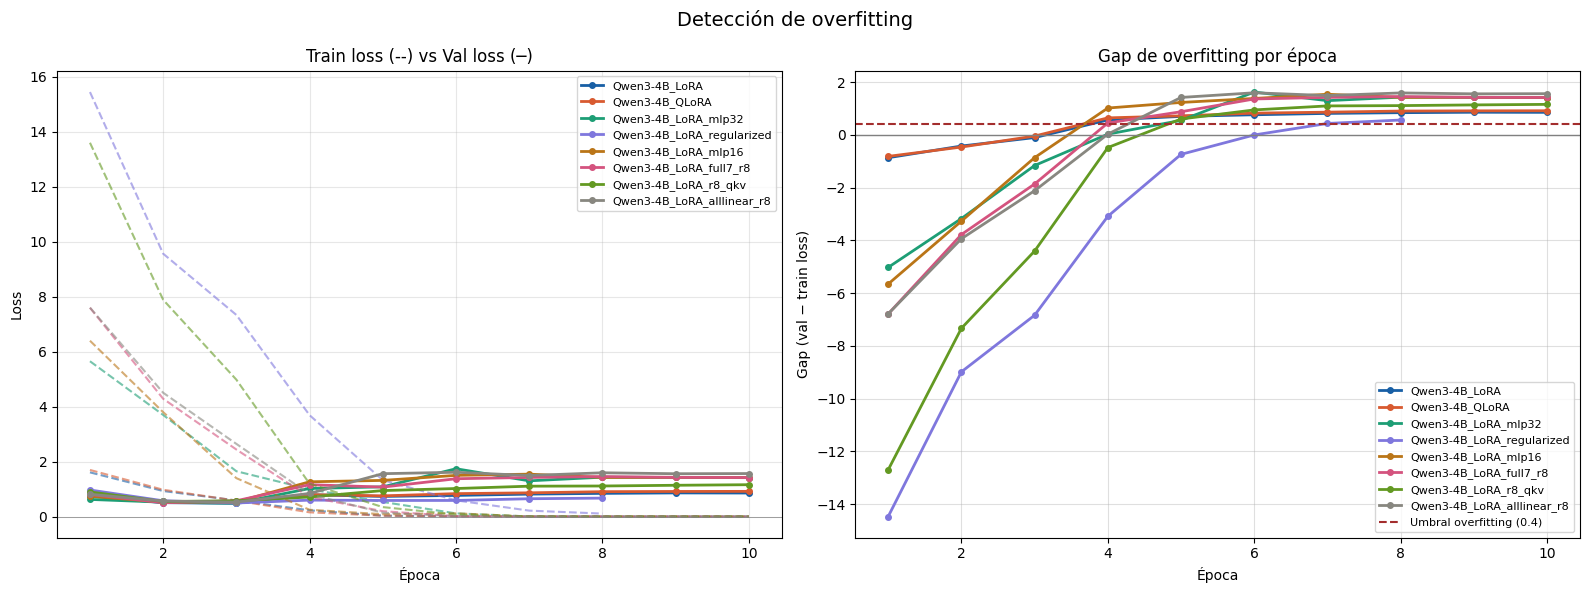

Guardado: /content/drive/MyDrive/TFM/comparativa/overfitting_cruzado.png


In [43]:
UMBRAL_GAP = 0.4
resumen_overfitting = []

if curvas:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for nombre, (epocas, f1_vals, val_loss, log_history) in curvas.items():
        color      = df_metrics.loc[df_metrics['modelo'] == nombre, 'color'].values[0]
        train_logs = [x for x in log_history if 'loss' in x and 'eval_loss' not in x]
        val_logs   = [x for x in log_history if 'eval_f1_macro' in x]

        if not train_logs or not val_logs:
            continue

        n_ep = len(val_logs)
        ppe  = max(len(train_logs) // n_ep, 1)
        train_loss_ep = [
            float(np.mean([x['loss'] for x in train_logs[max(0, (i+1)*ppe - ppe//2):(i+1)*ppe]]))
            for i in range(n_ep)
        ]
        val_loss_ep = [x['eval_loss'] for x in val_logs]
        gap         = [v - t for v, t in zip(val_loss_ep, train_loss_ep)]

        axes[0].plot(epocas, train_loss_ep, '--', linewidth=1.5, color=color, alpha=0.6)
        axes[0].plot(epocas, val_loss_ep,   '-',  linewidth=2,   color=color,
                     label=nombre, marker='o', markersize=4)
        axes[1].plot(epocas, gap, 'o-', linewidth=2, color=color, label=nombre, markersize=4)

        ep_ovf  = sum(1 for g in gap if g > UMBRAL_GAP)
        gap_ep3 = gap[2] if len(gap) > 2 else float('nan')
        flag    = 'BASTANTE' if gap[-1] > 0.8 else ('MEDIO' if gap[-1] > UMBRAL_GAP else 'OK')
        resumen_overfitting.append({
            'modelo': nombre, 'gap_ep3': round(gap_ep3, 3),
            'gap_final': round(gap[-1], 3), 'epocas_ovf': ep_ovf,
            'f1_best': round(max(f1_vals), 4), 'diagnostico': flag,
        })

    axes[0].axhline(0, color='gray', linewidth=0.5)
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Train loss (--) vs Val loss (─)')
    axes[0].legend(fontsize=8)
    axes[0].grid(True, alpha=0.3)

    axes[1].axhline(0,          color='gray',    linewidth=1,   linestyle='-')
    axes[1].axhline(UMBRAL_GAP, color='#A32D2D', linewidth=1.5, linestyle='--',
                    label=f'Umbral overfitting ({UMBRAL_GAP})')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Gap (val − train loss)')
    axes[1].set_title('Gap de overfitting por época')
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.4)

    plt.suptitle('Detección de overfitting', fontsize=14)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/overfitting_cruzado.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {OUTPUT_DIR}/overfitting_cruzado.png')

---
## 6. Análisis cruzado de errores

Carga los `val_predictions.csv` de cada modelo para comparar:

- **Errores totales** — cuántos artículos clasifica mal cada modelo.
- **Alertas ideológicas** — errores IZQUIERDA↔DERECHA, los más peligrosos
  porque invierten la orientación del artículo.
- **Errores con alta confianza** — el modelo muy seguro pero equivocado;
  estos son los más difíciles de detectar y los más dañinos para el reranking posterior.

In [44]:
df_val   = pd.read_parquet(SPLITS_DIR + '/df_val.parquet')
pred_dfs = {}

for _, row in df_metrics.iterrows():
    nombre = row['modelo']
    for csv_p in csv_paths:
        df_tmp  = pd.read_csv(csv_p)
        mod_csv = df_tmp.get('modelo', pd.Series([Path(csv_p).parent.name])).iloc[0]
        if mod_csv == nombre:
            pred_path = str(Path(csv_p).parent / 'val_predictions.csv')
            if os.path.exists(pred_path):
                pred_dfs[nombre] = pd.read_csv(pred_path)
                print(f'  OK  {nombre}')
            else:
                print(f'  --  {nombre}: val_predictions.csv no encontrado')
            break

print(f'\nPredicciones disponibles: {len(pred_dfs)}/{n_models}')

  OK  Qwen3-4B_LoRA
  OK  Qwen3-4B_QLoRA
  OK  Qwen3-4B_LoRA_mlp32
  OK  Qwen3-4B_LoRA_regularized
  OK  Qwen3-4B_LoRA_mlp16
  OK  Qwen3-4B_LoRA_full7_r8
  OK  Qwen3-4B_LoRA_r8_qkv
  OK  Qwen3-4B_LoRA_alllinear_r8

Predicciones disponibles: 8/8


In [45]:
if pred_dfs:
    resumen_errores = []
    for nombre, rv in pred_dfs.items():
        rv             = rv.copy()
        rv['correcto'] = rv['true'] == rv['pred']
        errores        = rv[~rv['correcto']]
        alertas        = errores[errores.apply(
            lambda r: set([r['true'], r['pred']]) == {'IZQUIERDA', 'DERECHA'}, axis=1
        )]
        high_conf_err  = errores[errores['confianza'] > 0.85]
        resumen_errores.append({
            'modelo':                   nombre,
            'errores_totales':          len(errores),
            'pct_error':                round(len(errores) / len(rv) * 100, 1),
            'alertas_ideologicas':      len(alertas),
            'errores_alta_confianza':   len(high_conf_err),
            'pct_alta_conf':            round(len(high_conf_err) / max(len(errores), 1) * 100, 1),
            'confianza_media_aciertos': round(rv[rv['correcto']]['confianza'].mean(), 4),
            'confianza_media_errores':  round(rv[~rv['correcto']]['confianza'].mean(), 4),
        })

    df_errores = pd.DataFrame(resumen_errores)
    orden      = df_metrics['modelo'].tolist()
    df_errores = df_errores.set_index('modelo').reindex(orden).reset_index()
    print(df_errores.to_string(index=False))

                    modelo  errores_totales  pct_error  alertas_ideologicas  errores_alta_confianza  pct_alta_conf  confianza_media_aciertos  confianza_media_errores
             Qwen3-4B_LoRA               34       14.3                    9                      26           76.5                    0.9676                   0.8912
            Qwen3-4B_QLoRA               34       14.3                    9                      22           64.7                    0.9739                   0.8742
       Qwen3-4B_LoRA_mlp32               35       14.7                   10                      32           91.4                    0.9838                   0.9506
 Qwen3-4B_LoRA_regularized               36       15.1                   11                      23           63.9                    0.9615                   0.8489
       Qwen3-4B_LoRA_mlp16               40       16.8                    9                       9           22.5                    0.9232                   0.7273
    

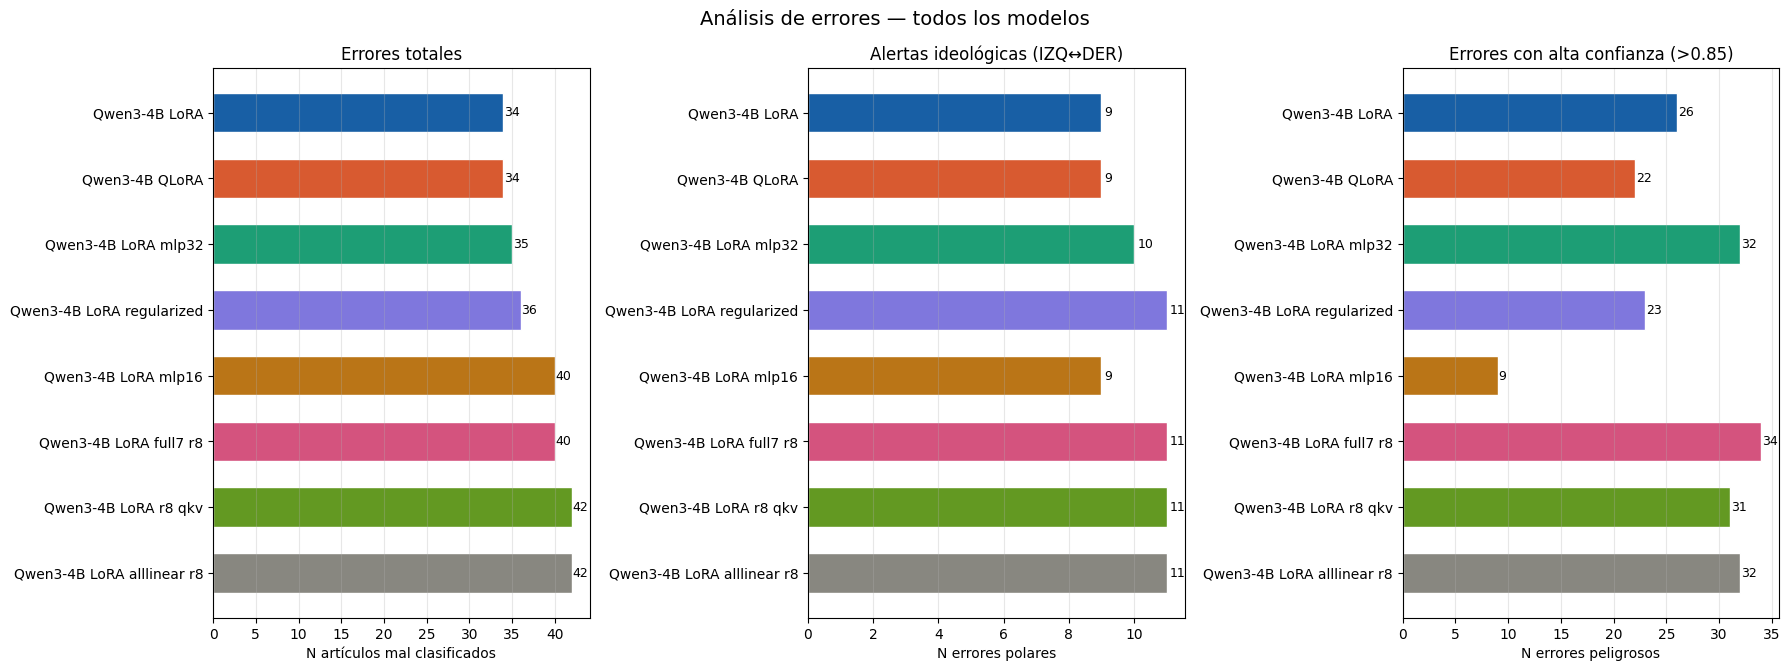

Guardado: /content/drive/MyDrive/TFM/comparativa/comparativa_errores.png


In [46]:
if pred_dfs and 'df_errores' in dir():
    fig, axes  = plt.subplots(1, 3, figsize=(18, max(5, n_models * 0.6 + 2)))
    x_err      = np.arange(len(df_errores))
    cols_err   = df_errores['modelo'].tolist()
    colores_err = [df_metrics.loc[df_metrics['modelo'] == m, 'color'].values[0] for m in cols_err]

    for ax, col, titulo, xlabel in [
        (axes[0], 'errores_totales',        'Errores totales',                   'N artículos mal clasificados'),
        (axes[1], 'alertas_ideologicas',    'Alertas ideológicas (IZQ↔DER)',     'N errores polares'),
        (axes[2], 'errores_alta_confianza', 'Errores con alta confianza (>0.85)', 'N errores peligrosos'),
    ]:
        vals = df_errores[col].tolist()
        ax.barh(x_err, vals, color=colores_err, edgecolor='white', height=0.6)
        ax.set_yticks(x_err)
        ax.set_yticklabels([m.replace('_',' ') for m in cols_err], fontsize=10)
        ax.set_title(titulo)
        ax.set_xlabel(xlabel)
        ax.grid(True, axis='x', alpha=0.3)
        ax.invert_yaxis()
        for i, v in enumerate(vals):
            ax.text(v + 0.1, i, str(v), va='center', fontsize=9)

    plt.suptitle('Análisis de errores — todos los modelos', fontsize=14)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/comparativa_errores.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {OUTPUT_DIR}/comparativa_errores.png')

---
## 9. Acuerdo entre modelos

Para cada artículo de validación se calcula en cuántos modelos coincide la predicción correcta.

- **Todos aciertan** → artículos con señal ideológica clara y consistente.
- **Ninguno acierta** → artículos ambiguos o con etiqueta discutible;
  candidatos prioritarios para revisión manual en el TFM.
- **Voto mayoritario** → predicción del ensemble; si supera al mejor modelo individual,
  combinar modelos es una estrategia válida para la inferencia final sobre los 238K artículos.

=== ENSEMBLE (voto mayoritario) ===
  Accuracy : 0.8655
  F1-macro : 0.8635
  Artículos donde TODOS aciertan : 164 / 238
  Artículos donde TODOS fallan   : 10 / 238


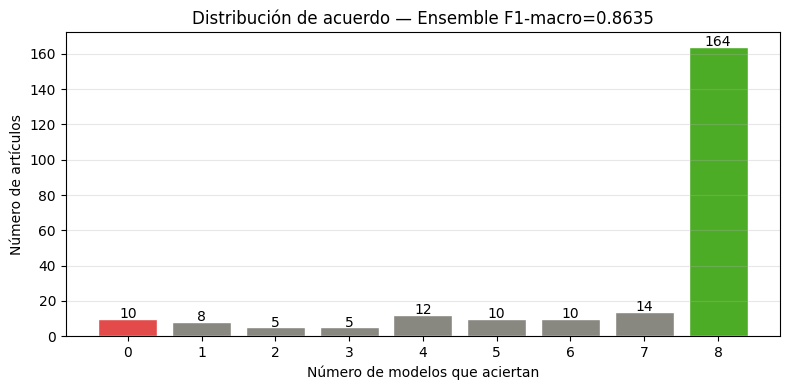

Guardado: /content/drive/MyDrive/TFM/comparativa/acuerdo_modelos.png

Artículos donde NINGÚN modelo acierta (primeros 5):
  ID: eldiario_10178 | Real: CENTRO | Preds: {'Qwen3-4B_LoRA': 'IZQUIERDA', 'Qwen3-4B_QLoRA': 'IZQUIERDA', 'Qwen3-4B_LoRA_mlp32': 'DERECHA', 'Qwen3-4B_LoRA_regularized': 'IZQUIERDA', 'Qwen3-4B_LoRA_mlp16': 'DERECHA', 'Qwen3-4B_LoRA_full7_r8': 'IZQUIERDA', 'Qwen3-4B_LoRA_r8_qkv': 'IZQUIERDA', 'Qwen3-4B_LoRA_alllinear_r8': 'DERECHA'}
  Vox tilda a Gan Pámpols de "enemigo en casa" de Mazón por refrendar las tesis del Gobierno sobre fondos europeos. José María Llanos (Vox) carga contra...

  ID: eldiario_16876 | Real: CENTRO | Preds: {'Qwen3-4B_LoRA': 'IZQUIERDA', 'Qwen3-4B_QLoRA': 'IZQUIERDA', 'Qwen3-4B_LoRA_mlp32': 'IZQUIERDA', 'Qwen3-4B_LoRA_regularized': 'IZQUIERDA', 'Qwen3-4B_LoRA_mlp16': 'IZQUIERDA', 'Qwen3-4B_LoRA_full7_r8': 'IZQUIERDA', 'Qwen3-4B_LoRA_r8_qkv': 'IZQUIERDA', 'Qwen3-4B_LoRA_alllinear_r8': 'IZQUIERDA'}
  El PP logra la mayoría absoluta en el Senado.

In [47]:
if len(pred_dfs) >= 2:
    base_id      = list(pred_dfs.values())[0]['id'].tolist()
    pred_matrix  = pd.DataFrame({'id': base_id})
    ground_truth = list(pred_dfs.values())[0].set_index('id')['true']

    for nombre, rv in pred_dfs.items():
        pred_matrix[nombre] = pred_matrix['id'].map(rv.set_index('id')['pred'])
    pred_matrix['true'] = pred_matrix['id'].map(ground_truth)
    pred_cols = list(pred_dfs.keys())

    pred_matrix['n_correctos'] = pred_matrix.apply(
        lambda r: sum(r[m] == r['true'] for m in pred_cols), axis=1)
    pred_matrix['todos_bien'] = pred_matrix['n_correctos'] == len(pred_cols)
    pred_matrix['todos_mal']  = pred_matrix['n_correctos'] == 0

    pred_matrix['voto_mayoritario'] = pred_matrix.apply(
        lambda r: Counter([r[m] for m in pred_cols]).most_common(1)[0][0], axis=1)
    pred_matrix['voto_correcto'] = pred_matrix['voto_mayoritario'] == pred_matrix['true']

    acc_ensemble = pred_matrix['voto_correcto'].mean()
    f1_ensemble  = f1_score(
        pred_matrix['true'].map(LABEL2ID),
        pred_matrix['voto_mayoritario'].map(LABEL2ID),
        average='macro', labels=[0,1,2], zero_division=0
    )

    print('=== ENSEMBLE (voto mayoritario) ===')
    print(f'  Accuracy : {acc_ensemble:.4f}')
    print(f'  F1-macro : {f1_ensemble:.4f}')
    print(f'  Artículos donde TODOS aciertan : {pred_matrix["todos_bien"].sum()} / {len(pred_matrix)}')
    print(f'  Artículos donde TODOS fallan   : {pred_matrix["todos_mal"].sum()} / {len(pred_matrix)}')

    fig, ax = plt.subplots(figsize=(8, 4))
    conteo  = pred_matrix['n_correctos'].value_counts().sort_index()
    bars    = ax.bar(
        conteo.index, conteo.values,
        color=['#E24B4A' if k == 0 else '#4dac26' if k == len(pred_cols) else '#888780'
               for k in conteo.index],
        edgecolor='white'
    )
    ax.set_xlabel('Número de modelos que aciertan')
    ax.set_ylabel('Número de artículos')
    ax.set_title(f'Distribución de acuerdo — Ensemble F1-macro={f1_ensemble:.4f}', fontsize=12)
    ax.set_xticks(range(len(pred_cols) + 1))
    ax.grid(True, axis='y', alpha=0.3)
    for bar, val in zip(bars, conteo.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                str(val), ha='center', fontsize=10)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR + '/acuerdo_modelos.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {OUTPUT_DIR}/acuerdo_modelos.png')

    if pred_matrix['todos_mal'].sum() > 0:
        print('\nArtículos donde NINGÚN modelo acierta (primeros 5):')
        casos = pred_matrix[pred_matrix['todos_mal']].merge(
            df_val[['id','texto']], on='id', how='left')
        for _, r in casos.head(5).iterrows():
            print(f"  ID: {r['id']} | Real: {r['true']} | Preds: { {m: r[m] for m in pred_cols} }")
            if 'texto' in r:
                print(f"  {str(r['texto'])[:150]}...")
            print()
else:
    print('Se necesitan al menos 2 modelos con predicciones para el análisis de acuerdo.')

In [48]:
# Exportar métricas
cols_export = [c for c in df_metrics.columns if c != 'color']
df_metrics[cols_export].to_csv(OUTPUT_DIR + '/tabla_comparativa_completa.csv', index=False)
print(f'Métricas guardadas        : {OUTPUT_DIR}/tabla_comparativa_completa.csv')

# Exportar hiperparámetros
df_params  = pd.DataFrame(todos_params)
cols_params = [c for c in df_params.columns if not c.startswith('_')]
df_params[cols_params].to_csv(OUTPUT_DIR + '/tabla_hiperparametros.csv', index=False)
print(f'Hiperparámetros guardados : {OUTPUT_DIR}/tabla_hiperparametros.csv')

# Exportar matriz de predicciones cruzadas
if 'pred_matrix' in dir() and len(pred_dfs) >= 2:
    pred_matrix.to_csv(OUTPUT_DIR + '/matriz_predicciones_cruzadas.csv', index=False)
    print(f'Matriz cruzada guardada   : {OUTPUT_DIR}/matriz_predicciones_cruzadas.csv')

print('\nArchivos en', OUTPUT_DIR + ':')
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(f'  {f}')

Métricas guardadas        : /content/drive/MyDrive/TFM/comparativa/tabla_comparativa_completa.csv
Hiperparámetros guardados : /content/drive/MyDrive/TFM/comparativa/tabla_hiperparametros.csv
Matriz cruzada guardada   : /content/drive/MyDrive/TFM/comparativa/matriz_predicciones_cruzadas.csv

Archivos en /content/drive/MyDrive/TFM/comparativa:
  acuerdo_modelos.png
  comparativa_errores.png
  comparativa_f1_por_clase.png
  comparativa_metricas_globales.png
  curvas_aprendizaje_comparativa.png
  finetuning_predictions
  matriz_predicciones_cruzadas.csv
  overfitting_cruzado.png
  radar_metricas.png
  tabla_comparativa_completa.csv
  tabla_hiperparametros.csv


---
## 10. Evaluación sobre el conjunto de test

Hasta aquí toda la comparativa se ha hecho sobre **validación**.
Esta sección evalúa los 8 modelos sobre el **test set** (238 artículos, nunca vistos durante el entrenamiento) y exporta los resultados en el formato que espera `5.3_comparativa_modelos.ipynb` en local.

Los modelos usan `AutoModelForSequenceClassification`: tienen cabeza de clasificación propia, así que la inferencia es directa y se pasa el texto al tokenizer y se leen los logits. Sin prompts.

In [49]:
NOMBRES_MODELOS = {
    'qwen3_4b_lora_mlp32':       'LoRA MLP-head r32',
    'qwen3_4b_lora_mlp16':        'LoRA MLP-head r8',   # la carpeta se quedó con nombre r16 pero es r8
    'qwen3_4b_lora_alllinear_r8': 'LoRA All-linear r8',
    'qwen3_4b_lora_full7_r8':     'LoRA Full-7layers r8',
    'qwen3_4b_lora_r8_qkv':       'LoRA QKV r8',
    'qwen3_4b_lora':              'LoRA QV r8',
    'qwen3_4b_lora_regularized':  'LoRA Regularized r8',
    'qwen3_4b_qlora':             'QLoRA QKV r8',
}

modelo_dirs = {Path(p).parent.name: str(Path(p).parent) for p in csv_paths}
print('Carpetas detectadas y nombres asignados:')
for k, v in modelo_dirs.items():
    print(f'  {k:<25} -> {NOMBRES_MODELOS.get(k, k)}')


Carpetas detectadas y nombres asignados:
  qwen3_4b_lora             -> LoRA QV r8
  qwen3_4b_lora_alllinear_r8 -> LoRA All-linear r8
  qwen3_4b_lora_full7_r8    -> LoRA Full-7layers r8
  qwen3_4b_lora_mlp16       -> LoRA MLP-head r8
  qwen3_4b_lora_mlp32       -> LoRA MLP-head r32
  qwen3_4b_lora_r8_qkv      -> LoRA QKV r8
  qwen3_4b_lora_regularized -> LoRA Regularized r8
  qwen3_4b_qlora            -> QLoRA QKV r8


### 10.1 Carga del test set

In [50]:
test_path = SPLITS_DIR + '/df_test.parquet'
assert os.path.exists(test_path), (
    f'No se encuentra {test_path}.\n'
    'Sube df_test.parquet desde tu Mac: data/splits/df_test.parquet -> Drive/TFM/splits/'
)

df_test    = pd.read_parquet(test_path)
y_true_str = df_test['final_label'].tolist()
y_true_int = [LABEL2ID[l] for l in y_true_str]

print(f'Test set: {len(df_test)} articulos')
print(f'Clases  : {df_test["final_label"].value_counts().to_dict()}')
print(f'Medios  : {df_test["medio"].value_counts().to_dict()}')

Test set: 238 articulos
Clases  : {'CENTRO': 96, 'IZQUIERDA': 84, 'DERECHA': 58}
Medios  : {'OKDiario': 46, 'elDiario.es': 43, 'Público': 41, 'El Confidencial': 39, 'El Mundo': 35, 'El País': 34}


### 10.2 Evaluación modelo a modelo

Carga cada adaptador, infiere sobre los 238 artículos del test y libera la GPU antes del siguiente.
La inferencia usa directamente la cabeza de clasificación del modelo (`AutoModelForSequenceClassification`): se pasa el texto al tokenizer y se leen los logits. Sin prompts, sin generación de texto.

In [56]:
MODEL_NAME    = "Qwen/Qwen3-4B"
QLORA_FOLDERS = {'qwen3_4b_qlora'}

# QLoRA: float16 en compute_dtype (bfloat16 no soportado en G4)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

OUTPUT_TEST_DIR = OUTPUT_DIR + '/finetuning_predictions'
os.makedirs(OUTPUT_TEST_DIR, exist_ok=True)

test_metrics = []

for folder_name, adapter_dir in modelo_dirs.items():
    nombre   = NOMBRES_MODELOS.get(folder_name, folder_name)
    best_dir = os.path.join(adapter_dir, 'best_model')
    load_dir = best_dir if os.path.isdir(best_dir) else adapter_dir

    if not os.path.exists(os.path.join(load_dir, 'adapter_config.json')):
        print(f'Saltando {nombre}: adapter_config.json no encontrado')
        continue

    print(f'\n{"="*55}')
    print(f'  {nombre}')
    print(f'{"="*55}')

    try:
        tokenizer = AutoTokenizer.from_pretrained(load_dir, trust_remote_code=True)
        if tokenizer.pad_token is None:
            tokenizer.pad_token    = tokenizer.eos_token
            tokenizer.pad_token_id = tokenizer.eos_token_id

        # QLoRA -> 4-bit; LoRA estándar
        if folder_name in QLORA_FOLDERS:
            bnb_config_qlora = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_storage=torch.float16,
            )
            base = AutoModelForSequenceClassification.from_pretrained(
                MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID,
                quantization_config=bnb_config_qlora, device_map="auto",
                torch_dtype=torch.float16,
                trust_remote_code=True,
            )
        else:
            base = AutoModelForSequenceClassification.from_pretrained(
                MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID,
                torch_dtype=torch.float16,
                device_map="auto", trust_remote_code=True,
            )

        model_t = PeftModel.from_pretrained(base, load_dir)
        model_t.config.pad_token_id = tokenizer.pad_token_id
        model_t.eval()

        ds = Dataset.from_dict({'texto': df_test['texto'].tolist()})
        ds = ds.map(
            lambda b: tokenizer(b['texto'], truncation=True, max_length=1024, padding=False),
            batched=True, remove_columns=['texto']
        )
        loader = DataLoader(ds, batch_size=16, collate_fn=DataCollatorWithPadding(tokenizer))

        all_probs = []
        with torch.no_grad():
            for batch in loader:
                batch  = {k: v.to("cuda") for k, v in batch.items()}
                logits = model_t(**batch).logits
                all_probs.append(torch.softmax(logits, dim=-1).cpu().numpy())

        probs  = np.vstack(all_probs)
        preds  = np.argmax(probs, axis=1)

        acc      = accuracy_score(y_true_int, preds)
        f1_macro = f1_score(y_true_int, preds, average='macro',    labels=[0,1,2], zero_division=0)
        f1_w     = f1_score(y_true_int, preds, average='weighted', labels=[0,1,2], zero_division=0)
        kappa    = cohen_kappa_score(y_true_int, preds)
        f1_per   = f1_score(y_true_int, preds, average=None, labels=[0,1,2], zero_division=0)

        print(f'  Accuracy={acc:.4f}  F1-macro={f1_macro:.4f}  Kappa={kappa:.4f}')
        print(f'  F1 IZQ={f1_per[0]:.4f}  CEN={f1_per[1]:.4f}  DER={f1_per[2]:.4f}')

        test_metrics.append({
            'Modelo': nombre, 'Accuracy': acc, 'F1-macro': f1_macro,
            'F1-weighted': f1_w, 'Kappa': kappa,
            'F1-IZQ': f1_per[0], 'F1-CEN': f1_per[1], 'F1-DER': f1_per[2],
            'Confianza': float(probs.max(axis=1).mean()),
        })

        pd.DataFrame({
            'id':          df_test['id'].tolist(),
            'medio':       df_test['medio'].tolist(),
            'true_label':  y_true_str,
            'pred_label':  [ID2LABEL[p] for p in preds],
            'confianza':   probs.max(axis=1).round(4).tolist(),
            'p_izquierda': probs[:, 0].round(4).tolist(),
            'p_centro':    probs[:, 1].round(4).tolist(),
            'p_derecha':   probs[:, 2].round(4).tolist(),
        }).to_csv(f'{OUTPUT_TEST_DIR}/{folder_name}.csv', index=False)

    except Exception as e:
        print(f'  Error: {e}')
    finally:
        try:
            del model_t, base
            torch.cuda.empty_cache(); gc.collect()
        except: pass

print(f'\nEvaluados {len(test_metrics)}/{len(modelo_dirs)} modelos')


  LoRA QV r8


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/238 [00:00<?, ? examples/s]

  Accuracy=0.8361  F1-macro=0.8212  Kappa=0.7467
  F1 IZQ=0.8521  CEN=0.8756  DER=0.7358

  LoRA All-linear r8


...

  Accuracy=0.8361  F1-macro=0.8205  Kappa=0.7466
  F1 IZQ=0.8621  CEN=0.8687  DER=0.7308

  QLoRA QKV r8


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/238 [00:00<?, ? examples/s]

  Accuracy=0.7857  F1-macro=0.7711  Kappa=0.6707
  F1 IZQ=0.8077  CEN=0.8333  DER=0.6724

Evaluados 8/8 modelos


### 10.3 Tabla resumen y exportación

Exporta `finetuning_test_metrics.csv` y la carpeta `finetuning_predictions/`.
Descárgalos a `output/` en tu Mac para usarlos en `5.3_comparativa_modelos.ipynb`.

In [63]:
df_test_metrics = (pd.DataFrame(test_metrics)
                   .sort_values('F1-macro', ascending=False)
                   .reset_index(drop=True))

print('=' * 85)
print('TABLA COMPARATIVA FINE-TUNING — TEST SET (n=238)')
print('=' * 85)
cols = ['Modelo', 'Accuracy', 'F1-macro', 'F1-IZQ', 'F1-CEN', 'F1-DER', 'Kappa']
print(df_test_metrics[cols].to_string(index=False, float_format='{:.4f}'.format))

# Delta val -> test
if 'f1_macro' in df_metrics.columns:
    # Mapeo directo nombre_legible
    test_a_val = {
        'LoRA QV r8':           'Qwen3-4B_LoRA',
        'LoRA All-linear r8':   'Qwen3-4B_LoRA_alllinear_r8',
        'LoRA Full-7layers r8': 'Qwen3-4B_LoRA_full7_r8',
        'LoRA MLP-head r8':     'Qwen3-4B_LoRA_mlp16',
        'LoRA MLP-head r32':    'Qwen3-4B_LoRA_mlp32',
        'LoRA QKV r8':          'Qwen3-4B_LoRA_r8_qkv',
        'LoRA Regularized r8':  'Qwen3-4B_LoRA_regularized',
        'QLoRA QKV r8':         'Qwen3-4B_QLoRA',
    }

    val_lookup = df_metrics.set_index('modelo')['f1_macro'].to_dict()

    cmp = df_test_metrics.copy()
    cmp['F1-macro (val)'] = cmp['Modelo'].map(
        {nombre: val_lookup[val_nombre]
         for nombre, val_nombre in test_a_val.items()
         if val_nombre in val_lookup}
    )
    cmp['Delta'] = (cmp['F1-macro'] - cmp['F1-macro (val)']).round(4)

    print('\nDelta val -> test (negativo = bajada respecto a val):')
    print(cmp[['Modelo', 'F1-macro (val)', 'F1-macro', 'Delta']]

          .to_string(index=False, float_format='{:.4f}'.format))
metrics_path = OUTPUT_DIR + '/finetuning_test_metrics.csv'
df_test_metrics.to_csv(metrics_path, index=False)
print(f'\nGuardado: {metrics_path}')
print(f'Predicciones: {OUTPUT_TEST_DIR}/')


TABLA COMPARATIVA FINE-TUNING — TEST SET (n=238)
              Modelo  Accuracy  F1-macro  F1-IZQ  F1-CEN  F1-DER  Kappa
         LoRA QKV r8    0.8403    0.8303  0.8571  0.8750  0.7586 0.7556
          LoRA QV r8    0.8361    0.8212  0.8521  0.8756  0.7358 0.7467
 LoRA Regularized r8    0.8361    0.8205  0.8621  0.8687  0.7308 0.7466
   LoRA MLP-head r32    0.8025    0.7904  0.8293  0.8410  0.7009 0.6977
  LoRA All-linear r8    0.7941    0.7792  0.7904  0.8500  0.6972 0.6825
    LoRA MLP-head r8    0.7941    0.7773  0.8293  0.8358  0.6667 0.6828
LoRA Full-7layers r8    0.7899    0.7723  0.8121  0.8246  0.6800 0.6728
        QLoRA QKV r8    0.7857    0.7711  0.8077  0.8333  0.6724 0.6707

Delta val -> test (negativo = bajada respecto a val):
              Modelo  F1-macro (val)  F1-macro   Delta
         LoRA QKV r8          0.8216    0.8303  0.0087
          LoRA QV r8          0.8556    0.8212 -0.0344
 LoRA Regularized r8          0.8460    0.8205 -0.0255
   LoRA MLP-head r32        